12 实盘窗口 10/1–10/24：09 策略 + STI 插槽（带成交账本）

**实盘结果文件。** 

策略：**90% × 09 的 6336 票投票** + **10% × 新加坡部分**（`11_sti_sleeve.ipynb`：ES3 比例由 10 号 GARCH 决定，其余持有 A35 债券；未接入时这 10% 放现金）。

规则：
- T 日收盘出信号，T+1 日开盘成交。起点是 LIVE_START 前最后一个收盘日出的信号，LIVE_START 开盘第一次建仓。
- 成本：每笔成交额 × 该标的单边 bps（00 里的 `ONE_WAY_BPS`），不折半、不加冲击成本。
- `REBALANCE = 'on_change'`：只在目标权重变化时交易；`'daily'`：每天调回目标（和 09 原回测一致）。
- 策略在 LIVE_START 当天冻结，窗口内不改规则。

文件依赖：`00_engine.ipynb`（已加入 `ONE_WAY_BPS`）、`09_parameter_ensemble.ipynb`、`11_sti_sleeve.ipynb`，数据 `data/raw/etf_daily.csv`（需含 `ES3.SI`、`A35.SI` 和 `SGD=X`，用 08 号下载）。


In [1]:
from pathlib import Path
import os, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)

def find_pipeline_dir():
    roots = ([Path(os.environ['ETF_PROJECT_ROOT']).expanduser()] if os.environ.get('ETF_PROJECT_ROOT') else [])
    roots += [Path.cwd(), *Path.cwd().parents]
    for root in roots:
        for cand in (root / 'pipeline', root):
            if (cand / '00_engine.ipynb').is_file() and (cand / '09_parameter_ensemble.ipynb').is_file():
                return cand.resolve()
    raise FileNotFoundError('找不到 pipeline 文件夹（需同时含 00 和 09）。')
PIPELINE_DIR = find_pipeline_dir()
ROOT = PIPELINE_DIR.parent if PIPELINE_DIR.name == 'pipeline' else PIPELINE_DIR      # 项目根目录
TABLE_DIR, FIG_DIR, SIGNAL_DIR = ROOT / 'results' / 'tables', ROOT / 'results' / 'figures', ROOT / 'results' / 'signals'

def load_notebook_definitions(filename):
    path = PIPELINE_DIR / filename
    nbk = json.loads(path.read_text(encoding='utf-8'))
    ns = {'__name__': 'pipeline_module'}
    for n, item in enumerate(nbk['cells']):
        if item['cell_type'] == 'code' and 'pipeline-entry' not in item.get('metadata', {}).get('tags', []):
            exec(compile(''.join(item['source']), f'{path}:cell{n}', 'exec'), ns)
    return ns

import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):          # 09 加载时会打印/显示参数表，这里静音
    _eng = load_notebook_definitions('00_engine.ipynb')
    _ens = load_notebook_definitions('09_parameter_ensemble.ipynb')
    _slv = load_notebook_definitions('11_sti_sleeve.ipynb')
TICKS = _eng['TICKS']; ONE_WAY_BPS = _eng['ONE_WAY_BPS']
IS_START = _eng['IS_START']
print('已加载 00 / 09 / 10。')


,rsi_n,spy_sma,overheat,oversold,uvxy_fear,uvxy_extreme,sqqq_line
0,7,100,70,20,64,80,30
1,7,100,70,20,64,80,34
2,7,100,70,20,64,80,38
3,7,100,70,20,64,84,30
4,7,100,70,20,64,84,34


已加载 00 / 09 / 10。


In [2]:
# ===== 只改这里 =====
CSV_PATH     = None            # None = 自动找 data/etf_daily.csv
LIVE_START   = '2026-10-01'
LIVE_END     = '2026-10-24'    # 10/24 是周六，实际取不晚于它的最后一个交易日
CAPITAL      = 100000.0
REBALANCE    = 'on_change'     # 'on_change' 只在目标权重变化时交易 | 'daily' 每天调回目标


1. 数据（ES3 换成美元；新加坡休市日用上一日价格）

In [3]:
df = _eng['load'](CSV_PATH)
df = df[df['Close']['SPY'].notna()]                      # 只保留美股交易日（否则新加坡单独开市日会产生 NaN 行）
f = df['Adj Close'][TICKS] / df['Close'][TICKS]
O9 = df['Open'][TICKS] * f; C9 = df['Adj Close'][TICKS].copy()

HAS_ES3 = ('ES3.SI' in df['Close'].columns) and ('SGD=X' in df['Close'].columns)
if HAS_ES3:
    fx = df['Close']['SGD=X'].ffill()                    # 1 美元 = 多少新元
    f2 = df['Adj Close']['ES3.SI'] / df['Close']['ES3.SI']
    eo = df['Open']['ES3.SI'] * f2 / fx
    ec = (df['Adj Close']['ES3.SI'] / fx).ffill()
    SG_CLOSED = eo.isna().values
    O_es3 = eo.where(eo.notna(), ec).ffill()
    local_close = df['Adj Close']['ES3.SI'].ffill()
    FX = fx.values
else:
    print('⚠ 数据里没有 ES3.SI / SGD=X：ES3 无法接入，这 10% 一律放现金。请用 08 重新下载含这两列的数据。')
    ec = pd.Series(1.0, index=df.index); O_es3 = ec.copy(); local_close = ec.copy()
    SG_CLOSED = np.zeros(len(df), bool); FX = np.ones(len(df))

HAS_A35 = HAS_ES3 and ('A35.SI' in df['Close'].columns)
if HAS_A35:
    f3 = df['Adj Close']['A35.SI'] / df['Close']['A35.SI']
    bo = df['Open']['A35.SI'] * f3 / fx
    bc = (df['Adj Close']['A35.SI'] / fx).ffill()
    SG_CLOSED_B = bo.isna().values
    O_a35 = bo.where(bo.notna(), bc).ffill()
else:
    if HAS_ES3:
        print('⚠ 数据里没有 A35.SI：A35 无法接入，新加坡部分未买 ES3 的资金放现金。请用 08 重新下载。')
    SG_CLOSED_B = np.zeros(len(df), bool)

O_all = O9.copy(); O_all['ES3'] = O_es3
C_all = C9.copy(); C_all['ES3'] = ec
if HAS_A35:
    O_all['A35'] = O_a35; C_all['A35'] = bc
NAMES = list(O_all.columns); idx = O_all.index
es3_px = pd.DataFrame({'open': O_es3, 'close': ec, 'local_close': local_close})
print('数据区间:', idx[0].date(), '~', idx[-1].date(), '| 最后一行请确认是收盘数据而不是盘中数据')


⚠ 数据里没有 ES3.SI / SGD=X：ES3 无法接入，这 10% 一律放现金。请用 08 重新下载含这两列的数据。
数据区间: 2011-10-03 ~ 2026-10-07 | 最后一行请确认是收盘数据而不是盘中数据


2. 09 的 6336 票投票 → 每日目标权重

In [4]:
weights, votes, valid_n = _ens['generate_ensemble_weights'](C9, start=IS_START, verbose=False)
print('投票完成，有效参数组数（正式期）:', int(valid_n.loc[IS_START:].max()))


投票完成，有效参数组数（正式期）: 6336


3. STI 插槽（10% 仓位）

In [5]:
SLEEVE_ON = HAS_ES3 and _slv['sleeve_is_connected'](es3_px)
sleeve_w = _slv['get_sleeve_weights'](es3_px) if HAS_ES3 else pd.Series(0.0, index=idx)
bond_w = _slv['get_bond_weights'](es3_px) if HAS_A35 else None
W = _slv['combine_with_sleeve'](weights, sleeve_w, bond_w=bond_w)
W = W.reindex(columns=NAMES).fillna(0.0)
print('ES3 插槽状态:', '已接入组员策略' if SLEEVE_ON else '【未接入】这 10% 放现金（结果只代表 90% 的投票部分）',
      '| A35:', '已接入' if (HAS_A35 and bond_w is not None and bond_w.abs().sum() > 0) else '未接入（放现金）')
print('目标权重行和（<1 的部分是现金）:', W.sum(axis=1).loc[LIVE_START:].round(3).unique()[:5])


ES3 插槽状态: 【未接入】这 10% 放现金（结果只代表 90% 的投票部分）
目标权重行和（<1 的部分是现金）: [0.9]


4. 带现金的成交账本

In [6]:
COST = np.array([ONE_WAY_BPS[t] for t in NAMES]) / 1e4
SG_TICKERS = {'ES3', 'A35'}                                 # 新加坡上市、以新元成交

def run_ledger(s, end, capital, rebalance):
    """第 s 个交易日收盘出信号，次日开盘成交。成本 = 成交额 × 单边 bps，从现金扣。"""
    Oa, Ca, Wa = O_all.to_numpy(float), C_all.to_numpy(float), W.to_numpy(float)
    sh = np.zeros(len(NAMES)); cash = capital; prev = None; trades, rows = [], []
    def snap(d, px):
        val = sh * px; eq = cash + val.sum()
        r = dict(date=d, equity=eq, cash=cash, cash_pct=cash / eq)
        for j, t in enumerate(NAMES):
            r[f'{t}_shares'] = sh[j]; r[f'{t}_value'] = val[j]; r[f'{t}_pct'] = val[j] / eq
        return r
    rows.append(snap(idx[s], Ca[s]))
    for k in range(s, end):
        d, w = idx[k + 1], Wa[k]
        if rebalance == 'daily' or prev is None or not np.allclose(w, prev, atol=1e-12):
            px = Oa[k + 1]; cur = sh * px; E = cash + cur.sum(); cost = np.zeros(len(NAMES))
            for _ in range(5):
                tgt = w * (E - cost.sum()); delta = tgt - cur; cost = np.abs(delta) * COST
            for j in np.where(np.abs(delta) > 0.01)[0]:
                t = NAMES[j]
                trades.append(dict(exec_date=d, signal_date=idx[k], ticker=t,
                    side='BUY' if delta[j] > 0 else 'SELL', shares=abs(delta[j]) / px[j],
                    price_usd=px[j], price_local=px[j] * FX[k + 1] if t in SG_TICKERS else px[j],
                    currency='SGD' if t in SG_TICKERS else 'USD', notional_usd=abs(delta[j]),
                    cost_bps=COST[j] * 1e4, cost_usd=cost[j], weight_before=cur[j] / E,
                    weight_after=tgt[j] / (E - cost.sum()),
                    note='新加坡休市，按上一日价格' if ((t == 'ES3' and SG_CLOSED[k + 1]) or (t == 'A35' and SG_CLOSED_B[k + 1])) else ''))
            sh = sh + delta / px; cash = E - tgt.sum() - cost.sum(); prev = w.copy()
        rows.append(snap(d, Ca[k + 1]))
    return pd.DataFrame(trades), pd.DataFrame(rows).set_index('date')

ls, le = pd.Timestamp(LIVE_START), pd.Timestamp(LIVE_END)
s = int(np.where(idx < ls)[0][-1])                         # LIVE_START 前最后一个收盘日出信号
end = int(np.where(idx <= le)[0][-1])                      # 不晚于 LIVE_END 的最后一个交易日
if idx[-1] < le: print(f'窗口未完成：计划到 {LIVE_END}，数据只到 {idx[-1].date()}')
assert W.iloc[s].sum() > 0, '起点没有有效信号'
trades, daily = run_ledger(s, end, CAPITAL, REBALANCE)
print(f'信号日 {idx[s].date()} → 首次建仓 {idx[s+1].date()} 开盘 | 回测到 {idx[end].date()} | 成交 {len(trades)} 笔')


窗口未完成：计划到 2026-10-24，数据只到 2026-10-07
信号日 2026-09-30 → 首次建仓 2026-10-01 开盘 | 回测到 2026-10-07 | 成交 7 笔


5. 汇总

In [7]:
eq = daily['equity']; mdd = (eq / eq.cummax() - 1).min()
rows = [dict(方案=f'策略（插槽{"已接入" if SLEEVE_ON else "未接入"}）', 区间=f'{idx[s+1].date()}~{idx[end].date()}',
             交易日=len(eq) - 1, 期末资产=round(eq.iloc[-1], 2), 累计收益=f'{eq.iloc[-1]/CAPITAL-1:+.2%}',
             最大回撤=f'{mdd:.2%}', 成交笔数=len(trades), 总成本USD=round(trades.cost_usd.sum(), 2) if len(trades) else 0.0)]
for t in ['SPY', 'QQQ', 'TQQQ']:
    e = C_all[t].iloc[s:end + 1]
    rows.append(dict(方案='买入持有 ' + t, 区间=f'{idx[s+1].date()}~{idx[end].date()}', 交易日=len(e) - 1,
                     期末资产=round(CAPITAL * e.iloc[-1] / e.iloc[0], 2), 累计收益=f'{e.iloc[-1]/e.iloc[0]-1:+.2%}',
                     最大回撤=f'{(e/e.cummax()-1).min():.2%}', 成交笔数=1, 总成本USD=np.nan))
summary = pd.DataFrame(rows); display(summary)
print('使用的单边成本 bps:', {t: ONE_WAY_BPS[t] for t in NAMES})


,方案,区间,交易日,期末资产,累计收益,最大回撤,成交笔数,总成本USD
0,策略（插槽未接入）,2026-10-01~2026-10-07,5,104325.59,+4.33%,-0.89%,7,36.33
1,买入持有 SPY,2026-10-01~2026-10-07,5,101913.11,+1.91%,-0.24%,1,NaN
2,买入持有 QQQ,2026-10-01~2026-10-07,5,102427.78,+2.43%,-0.25%,1,NaN
3,买入持有 TQQQ,2026-10-01~2026-10-07,5,107163.92,+7.16%,-0.75%,1,NaN


使用的单边成本 bps: {'SPY': 0.5, 'QQQ': 1.5, 'TQQQ': 1.0, 'UVXY': 6.0, 'TECL': 35.0, 'SPXL': 16.0, 'SQQQ': 3.0, 'TECS': 15.0, 'BSV': 1.0, 'ES3': 18.0}


6. 成交明细（日期、标的、方向、股数、价格、金额、成本）

In [8]:
show = trades.copy()
if len(show):
    show['exec_date'] = show.exec_date.dt.date; show['signal_date'] = show.signal_date.dt.date
    display(show.round({'shares': 2, 'price_usd': 3, 'price_local': 3, 'notional_usd': 2, 'cost_bps': 2, 'cost_usd': 2,
                        'weight_before': 4, 'weight_after': 4}))


,exec_date,signal_date,ticker,side,shares,price_usd,price_local,currency,notional_usd,cost_bps,cost_usd,weight_before,weight_after,note
0,2026-10-01,2026-09-30,TQQQ,BUY,1140.87,78.88,78.88,USD,89991.90,1.0,9.00,0.0000,0.900,
1,2026-10-05,2026-10-02,TQQQ,SELL,97.80,80.95,80.95,USD,7917.06,1.0,0.79,0.9023,0.825,
2,2026-10-05,2026-10-02,UVXY,BUY,456.91,16.80,16.80,USD,7676.04,6.0,4.61,0.0000,0.075,
3,2026-10-06,2026-10-05,TQQQ,SELL,197.87,84.54,84.54,USD,16727.96,1.0,1.67,0.8329,0.675,
4,2026-10-06,2026-10-05,UVXY,BUY,1003.41,16.31,16.31,USD,16365.55,6.0,9.82,0.0704,0.225,
5,2026-10-07,2026-10-06,TQQQ,SELL,179.80,82.32,82.32,USD,14801.02,1.0,1.48,0.6668,0.525,
6,2026-10-07,2026-10-06,UVXY,BUY,902.34,16.56,16.56,USD,14942.75,6.0,8.97,0.2318,0.375,


7. 每日持仓与当前持仓

In [9]:
cols = ['equity', 'cash', 'cash_pct'] + [f'{t}_pct' for t in NAMES]
display(daily[cols].round(4))
last = daily.iloc[-1]
holdings = pd.DataFrame({'shares': [last[f'{t}_shares'] for t in NAMES], 'value_usd': [last[f'{t}_value'] for t in NAMES],
                         'weight': [last[f'{t}_pct'] for t in NAMES]}, index=NAMES)
holdings.loc['CASH'] = [np.nan, last['cash'], last['cash_pct']]
holdings = holdings[(holdings.value_usd.abs() > 0.01)]
print('当前持仓（截至', daily.index[-1].date(), '收盘）:'); display(holdings.round(4))

tgt_next = W.iloc[end]; nxt = pd.DataFrame({'目标权重': tgt_next, '当前权重': [last[f'{t}_pct'] for t in NAMES]}, index=NAMES)
nxt = nxt[(nxt.abs() > 1e-9).any(axis=1)]
print('最新信号（', idx[end].date(), '收盘）→ 下一个交易日开盘的目标:'); display(nxt.round(4))


,equity,cash,cash_pct,SPY_pct,QQQ_pct,TQQQ_pct,UVXY_pct,TECL_pct,SPXL_pct,SQQQ_pct,TECS_pct,BSV_pct,ES3_pct
date,,,,,,,,,,,,,
2026-09-30,100000.0000,100000.0000,1.0000,0.0,0.0,0.0000,0.0000,0.0,0.0,0.0,0.0,0.0,0.0
2026-10-01,99819.8771,9999.1001,0.1002,0.0,0.0,0.8998,0.0000,0.0,0.0,0.0,0.0,0.0,0.0
2026-10-02,102421.0616,9999.1001,0.0976,0.0,0.0,0.9024,0.0000,0.0,0.0,0.0,0.0,0.0,0.0
2026-10-05,104560.4130,10234.7206,0.0979,0.0,0.0,0.8292,0.0729,0.0,0.0,0.0,0.0,0.0,0.0
2026-10-06,105260.8688,10585.6452,0.1006,0.0,0.0,0.6765,0.2229,0.0,0.0,0.0,0.0,0.0,0.0
2026-10-07,104325.5853,10433.4742,0.1000,0.0,0.0,0.5333,0.3667,0.0,0.0,0.0,0.0,0.0,0.0


当前持仓（截至 2026-10-07 收盘）:


,shares,value_usd,weight
TQQQ,665.4001,55640.7618,0.5333
UVXY,2362.6528,38251.3493,0.3667
CASH,NaN,10433.4742,0.1000


最新信号（ 2026-10-07 收盘）→ 下一个交易日开盘的目标:


,目标权重,当前权重
TQQQ,0.675,0.5333
UVXY,0.225,0.3667


8. 图与保存

已保存到 E:\desktop\nus\5209\vol_target_rotation\results （tables / figures / signals）


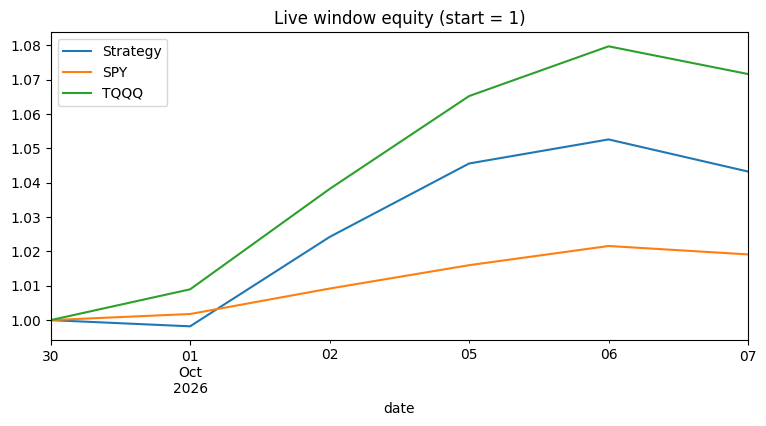

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
(eq / CAPITAL).plot(ax=ax, label='Strategy')
for t in ['SPY', 'TQQQ']:
    e = C_all[t].iloc[s:end + 1]; (e / e.iloc[0]).plot(ax=ax, label=t)
ax.set_title('Live window equity (start = 1)'); ax.legend()

for d in (TABLE_DIR, FIG_DIR, SIGNAL_DIR): d.mkdir(parents=True, exist_ok=True)
fig.savefig(FIG_DIR / 'live_oct_equity.png', dpi=150, bbox_inches='tight')
trades.to_csv(TABLE_DIR / 'live_oct_trades.csv', index=False, encoding='utf-8-sig')
daily.to_csv(TABLE_DIR / 'live_oct_daily_positions.csv', encoding='utf-8-sig')
holdings.to_csv(TABLE_DIR / 'live_oct_current_holdings.csv', encoding='utf-8-sig')
summary.to_csv(TABLE_DIR / 'live_oct_summary.csv', index=False, encoding='utf-8-sig')
nxt.to_csv(SIGNAL_DIR / 'live_oct_next_open_target.csv', encoding='utf-8-sig')
print('已保存到', ROOT / 'results', '（tables / figures / signals）')
plt.show()
